# SCENIC+ 2: Motif enrichment

*cisTarget and DEM.*

SCENIC+ links transcription factors to enhancers by asking which TF motifs are
enriched in sets of co-accessible regions: topics, cell-type DARs or marker
peaks. It uses two complementary tests, implemented upstream by
[pycistarget](https://github.com/aertslab/pycistarget):

* **cisTarget**: recovery-curve AUC of each motif's genome-wide region
  ranking, normalised to an NES over all motifs. Leading-edge regions are the
  motif hits.
* **DEM** (differentially enriched motifs): a Wilcoxon test on motif scores of
  a foreground set against a GC/promoter-balanced background drawn from the
  other sets.

`epione.scenic` reimplements both, plus the cistrome merging that feeds the
SCENIC+ eGRN step. The code is plain numpy/numba and depends on neither
pycistarget nor ctxcore, pyranges or polars. Results are bit-identical to
pycistarget 1.1 on the official SCENIC+ tutorial run (parity table at the
end). It is about 9× faster for cisTarget and 4× faster for DEM. The gain
comes from reading each database column once, replacing the dense
recovery-curve matrix with a single streaming pass, and computing rank sums
from sorted rows.

Two motif backends are shown:

1. the **official Aerts-lab cisTarget databases** (hg38 SCREEN v10, 1.8 M
   regions × 5,876 motifs), the setting SCENIC+ uses;
2. **Epione's own MOODS + JASPAR scan** of your peaks, turned into a scores and
   rankings database. It needs no external database and works for any genome
   with a FASTA.

Data: the 10x multiome human cerebellum 3k sample used by the SCENIC+ 1.0
tutorial, with the authors' cell-type annotation.

In [1]:
import os, time
from pathlib import Path

import numpy as np
import pandas as pd
import pooch
import matplotlib.pyplot as plt

import epione as epi

DATA = Path(os.environ.get("EPIONE_DATA_DIR") or pooch.os_cache("epione"))
N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK", 8))
print("data directory:", DATA, "| workers:", N_JOBS)

data directory: data | workers: 8


## 1. Data

Fragments and ATAC peaks come from 10x Genomics. The cell annotation
(`VSN_cell_type`) comes from the pycisTopic repository. All files are cached
by pooch and checked against pinned hashes.

In [2]:
CERE = DATA / "scenic_cerebellum"
URL10X = "https://cf.10xgenomics.com/samples/cell-arc/2.0.0/human_brain_3k/"
files = {
    "human_brain_3k_atac_fragments.tsv.gz": (URL10X, "sha256:dd3513999f458e97fdf635cc0641df337c734119b122074da9dcfda17af17226"),
    "human_brain_3k_atac_fragments.tsv.gz.tbi": (URL10X, "sha256:7d89aae2ebef104d8491bedf5cccdbe3fe69d53a142071019a7ed2739b85fdd6"),
    "human_brain_3k_atac_peaks.bed": (URL10X, "sha256:b92d45dccbf2c49b7cdec8e9a2f0fd755d7b3a712de7c778dddf9a29cdb66f8f"),
    "cell_data_human_cerebellum.tsv": ("https://raw.githubusercontent.com/aertslab/pycisTopic/polars/data/",
                                       "sha256:e762f44f1a6523614c019419bf8971da536bba72ca5a0322d0e1b215f863a56c"),
}
paths = {f: pooch.retrieve(base + f, known_hash=h, path=CERE, fname=f) for f, (base, h) in files.items()}
# show paths relative to the working directory when they live below it
paths = {f: os.path.relpath(p) if p.startswith(os.getcwd()) else p for f, p in paths.items()}

cell_data = pd.read_csv(paths["cell_data_human_cerebellum.tsv"], sep="\t", index_col=0)
cell_data.index = cell_data.index.str.replace("-10x_multiome_brain", "", regex=False)
peaks = pd.read_csv(paths["human_brain_3k_atac_peaks.bed"], sep="\t", comment="#", header=None,
                    usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
peaks = peaks[peaks["Chromosome"].str.match(r"^chr[0-9XY]+$")].reset_index(drop=True)
print(f"{len(cell_data):,} annotated cells, {len(peaks):,} peaks")
cell_data["VSN_cell_type"].value_counts()

2,392 annotated cells, 133,986 peaks


VSN_cell_type
MOL_A        619
MOL_B        579
AST_CER      317
OPC          185
GC           134
INH_VIP      124
INH_SST      124
MGL           77
ASTP          73
GP            56
AST           36
PURK          30
INH_PVALB     20
ENDO          18
Name: count, dtype: int64

## 2. Region sets: cell-type marker peaks

Any collection of region sets works, such as topics, DARs or co-accessible
modules. Here each cell type gets its marker peaks from Epione's own pipeline:
fragments → peak matrix → bias-matched Wilcoxon markers.

In [3]:
t0 = time.perf_counter()
adata = epi.pp.import_fragments(paths["human_brain_3k_atac_fragments.tsv.gz"], chrom_sizes=epi.data.hg38,
                                whitelist=list(cell_data.index), min_num_fragments=0)
names = (peaks["Chromosome"] + ":" + peaks["Start"].astype(str) + "-" + peaks["End"].astype(str)).tolist()
pm = epi.pp.make_peak_matrix(adata, use_rep=names)
pm.obs["cell_type"] = cell_data.loc[pm.obs_names, "VSN_cell_type"].astype("category").values
pm.obs["log_n_fragment"] = np.log10(adata.obs.loc[pm.obs_names, "n_fragment"].values)
print(pm, f"\n{time.perf_counter() - t0:.0f} s")

└─ scanning data/scenic_cerebellum/human_brain_3k_atac_fragments.tsv.gz


  └─ imported 2,392 cells  (79,805,474 unique fragments)


└─ building peak matrix: 2,392 cells × 133,986 peaks


  └─ peak matrix nnz=21,862,757
AnnData object with n_obs × n_vars = 2392 × 133986
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'cell_type', 'log_n_fragment'
    uns: 'files', 'reference_sequences' 
329 s


In [4]:
keep_types = [c for c, n in pm.obs["cell_type"].value_counts().items() if n >= 30]
markers = epi.tl.find_marker_features(pm, group_by="cell_type", groups=keep_types,
                                      bias_vars=["log_n_fragment"], seed=0)
sig = markers[(markers["fdr"] < 0.05) & (markers["log2_fc"] > np.log2(1.5))]
region_sets = {
    ct: sig[sig["group"] == ct].nlargest(2000, "z")["feature"].tolist()
    for ct in keep_types
}
region_sets = {k: v for k, v in region_sets.items() if len(v) >= 100}
pd.Series({k: len(v) for k, v in region_sets.items()}, name="marker peaks")

  └─ [find_marker_features] group='MOL_A' | fg=619 cells | bg=408 cells (matched=yes)


  └─ [find_marker_features] group='MOL_B' | fg=579 cells | bg=430 cells (matched=yes)


  └─ [find_marker_features] group='AST_CER' | fg=317 cells | bg=251 cells (matched=yes)


  └─ [find_marker_features] group='OPC' | fg=185 cells | bg=168 cells (matched=yes)


  └─ [find_marker_features] group='GC' | fg=134 cells | bg=104 cells (matched=yes)


...

  └─ [find_marker_features] group='ASTP' | fg=73 cells | bg=73 cells (matched=yes)


  └─ [find_marker_features] group='GP' | fg=56 cells | bg=52 cells (matched=yes)


  └─ [find_marker_features] group='AST' | fg=36 cells | bg=36 cells (matched=yes)


  └─ [find_marker_features] group='PURK' | fg=30 cells | bg=29 cells (matched=yes)


MOL_A      1448
MOL_B      2000
AST_CER    2000
OPC        2000
GC         2000
INH_SST    2000
INH_VIP    2000
MGL        2000
ASTP        268
Name: marker peaks, dtype: int64

## 3. cisTarget and DEM with the official databases

`fetch_cistarget_database` downloads the region-based SCREEN v10 databases
(rankings 35 GB, scores 14 GB). The files are cached, and only the columns
that overlap the region sets are decompressed and read, once for all sets.

In [5]:
rankings = epi.scenic.CisTargetDB(epi.scenic.fetch_cistarget_database("hg38", kind="rankings", data_dir=DATA))
scores = epi.scenic.CisTargetDB(epi.scenic.fetch_cistarget_database("hg38", kind="scores", data_dir=DATA))
annotation = epi.scenic.load_motif_annotations(epi.scenic.fetch_motif_annotation("homo_sapiens", data_dir=DATA))
rankings, scores, annotation.shape

(CisTargetDB('hg38_screen_v10_clust.regions_vs_motifs.rankings.feather', kind=rankings, 1,837,304 regions × 5,876 motifs),
 CisTargetDB('hg38_screen_v10_clust.regions_vs_motifs.scores.feather', kind=scores, 1,837,304 regions × 5,876 motifs),
 (27072, 4))

In [6]:
t0 = time.perf_counter()
ctx = epi.scenic.run_cistarget(region_sets, rankings, motif_annotation=annotation)
print(f"cisTarget: {time.perf_counter() - t0:.0f} s")
ctx[next(iter(ctx))]

  └─ [scenic] reading 26,343 database regions × 5,876 motifs


  └─ [scenic] database read in 10.2 s


  └─ [scenic] MOL_A: 2,466 db regions, 75 enriched motifs


  └─ [scenic] MOL_B: 3,625 db regions, 78 enriched motifs


  └─ [scenic] AST_CER: 3,778 db regions, 152 enriched motifs


...

  └─ [scenic] MGL: 3,837 db regions, 98 enriched motifs


  └─ [scenic] ASTP: 543 db regions, 132 enriched motifs


  └─ [scenic] cisTarget done in 12.8 s


cisTarget: 13 s


MotifEnrichmentResult(cisTarget 'MOL_A': 75 motifs, 102 cistromes)

In [7]:
def top_tfs(results, n=6, col="NES"):
    rows = {}
    for name, r in results.items():
        me = r.motif_enrichment.dropna(subset=["Direct_annot"])
        tfs = []
        for cell in me.sort_values(col, ascending=False)["Direct_annot"]:
            for t in cell.split(", "):
                if t not in tfs:
                    tfs.append(t)
            if len(tfs) >= n:
                break
        rows[name.replace("cell_type_", "").replace("_vs_all", "")] = ", ".join(tfs[:n])
    return pd.Series(rows, name=f"top TFs by {col}")

top_tfs(ctx).to_frame()

,top TFs by NES
MOL_A,"SOX10, SOX18, SOX8, SOX9, HBP1, SOX1"
MOL_B,"SOX10, SOX18, SOX8, SOX9, HBP1, SOX1"
AST_CER,"NFIC, NFIA, NFIB, NFIX, MIXL1, RAX2"
OPC,"ZBTB14, E2F2, SOX10, SOX18, SOX8, SOX9"
GC,"ATF3, BACH2, BATF, BATF3, FOS, FOSB"
INH_SST,"MEF2A, MEF2B, MEF2C, MEF2D, ZBTB18, ASCL1"
INH_VIP,"NEUROG2, TAL1, ZBTB18, MYOG, MEF2A, MEF2B"
MGL,"EHF, ELF5, NFATC3, SPI1, SPIB, SPIC"
ASTP,"ARGFX, LBX2, TAF6, TBP, LHX9, PAX4"


The top motifs match the known regulators of each cell type:

| Cell type | Top motifs |
|---|---|
| Oligodendrocytes (MOL) and OPCs | SOX10 / SOXE |
| Cerebellar astrocytes (AST_CER) | NFI |
| Granule cells (GC) | AP-1 (FOS / ATF / BATF), the activity-dependent program |
| SST interneurons | MEF2 and the neuronal bHLH factors ASCL1 / ZBTB18 |
| VIP interneurons | MEF2 and NEUROG2 |
| Microglia (MGL) | the ETS factors SPI1 / SPIB (PU.1) |

DEM tests each cell type's markers against a background of the other cell
types' markers. The background is balanced for promoter content, with
promoters taken as gene starts ± 1 kb.

In [8]:
gff = epi.data.hg38.annotation
genes = pd.read_csv(gff, sep="\t", comment="#", header=None, usecols=[0, 2, 3, 4, 6, 8],
                    names=["Chromosome", "type", "Start", "End", "Strand", "attr"])
genes = genes[(genes["type"] == "gene") & genes["attr"].str.contains("gene_type=protein_coding")]
genome_annotation = genes[["Chromosome", "Start", "End", "Strand"]].reset_index(drop=True)

t0 = time.perf_counter()
dem = epi.scenic.run_dem({"cell_type": region_sets}, scores, genome_annotation=genome_annotation,
                         motif_annotation=annotation)
print(f"DEM: {time.perf_counter() - t0:.0f} s")
top_tfs(dem, col="Log2FC").to_frame()

  └─ [scenic] reading 26,343 database regions × 5,876 motifs


  └─ [scenic] database read in 24.3 s


  └─ [scenic] cell_type_MOL_A_vs_all: 6 enriched motifs


  └─ [scenic] cell_type_MOL_B_vs_all: 4 enriched motifs


  └─ [scenic] cell_type_AST_CER_vs_all: 7 enriched motifs


...

  └─ [scenic] cell_type_MGL_vs_all: 20 enriched motifs


  └─ [scenic] cell_type_ASTP_vs_all: 0 enriched motifs


  └─ [scenic] DEM done in 26.5 s


DEM: 27 s


,top TFs by Log2FC
MOL_A,"FOXO1, YY2, SOX17, SOX9"
MOL_B,"SOX9, SMAD1, SOX4"
AST_CER,"LHX9, POU6F2, EN1, ALX1, MNX1, PAX4"
OPC,E2F2
GC,"EGR2, EGR4, BACH1"
INH_SST,
INH_VIP,
MGL,"SPIB, TEAD4, ETV6, ELF2, ATF5, NKX3-2"
ASTP,


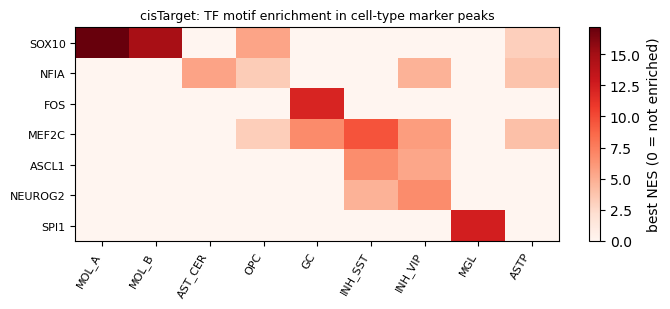

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
genes_show = ["SOX10", "NFIA", "FOS", "MEF2C", "ASCL1", "NEUROG2", "SPI1"]
nes = pd.DataFrame(0.0, index=genes_show, columns=list(ctx))
for name, r in ctx.items():
    me = r.motif_enrichment.dropna(subset=["Direct_annot"])
    for g in genes_show:
        hit = me[me["Direct_annot"].str.split(", ").apply(lambda x: g in x)]
        nes.loc[g, name] = hit["NES"].max() if len(hit) else 0.0
im = ax.imshow(nes.values, cmap="Reds", vmin=0, aspect="auto")
ax.set_xticks(range(nes.shape[1]), nes.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(nes.shape[0]), nes.index, fontsize=8)
fig.colorbar(im, ax=ax, label="best NES (0 = not enriched)")
ax.set_title("cisTarget: TF motif enrichment in cell-type marker peaks", fontsize=9)
fig.tight_layout()

### Cistromes for SCENIC+

`merge_cistromes` turns all cisTarget and DEM results into the two
region × TF matrices that the eGRN step uses: **direct** (motif annotated to
the TF) and **extended** (orthology). It is restricted to the regions of the
ATAC object. This is scenicplus' `prepare_menr`.

In [10]:
direct, extended = epi.scenic.merge_cistromes([dem, ctx], scplus_regions=pm.var_names)
print(direct)
print(extended)
direct.var.head()

AnnData object with n_obs × n_vars = 13081 × 554
    var: 'motifs', 'is_extended'
AnnData object with n_obs × n_vars = 10661 × 292
    var: 'motifs', 'is_extended'


,motifs,is_extended
AIRE,metacluster_129.1,False
ALX1,metacluster_9.24,False
ALX3,"metacluster_150.6,metacluster_161.6,metacluste...",False
ALX4,"metacluster_150.6,metacluster_161.26",False
ARGFX,"metacluster_112.2,metacluster_150.5",False


## 4. Without external databases: Epione's MOODS + JASPAR backend

`motif_score_db` scans the peaks with MOODS (JASPAR 2024 CORE vertebrates,
p < 1e-4). The score is the best log-odds hit per peak and motif.
`scores_to_rankings` ranks peaks per motif, breaking ties with a seeded
permutation. Both objects behave like the official databases. JASPAR motif
names carry their TF, so `jaspar_annotation` builds the motif → TF table.

In [11]:
t0 = time.perf_counter()
moods_scores = epi.scenic.motif_score_db(peaks, genome_fasta=epi.data.hg38.fasta, n_jobs=N_JOBS, verbose=False)
moods_rankings = epi.scenic.scores_to_rankings(moods_scores, seed=555)
jaspar = epi.scenic.jaspar_annotation(moods_scores.motifs)
print(moods_scores, moods_rankings, f"{time.perf_counter() - t0:.0f} s", sep="\n")

CisTargetDB('epione_moods', kind=scores, 133,986 regions × 879 motifs)
CisTargetDB('epione_moods', kind=rankings, 133,986 regions × 879 motifs)
91 s


In [12]:
ctx_moods = epi.scenic.run_cistarget(region_sets, moods_rankings, motif_annotation=jaspar, verbose=False)
dem_moods = epi.scenic.run_dem({"cell_type": region_sets}, moods_scores, genome_annotation=genome_annotation,
                               motif_annotation=jaspar, motif_hit_thr=None, verbose=False)
pd.concat({"official cisTarget": top_tfs(ctx), "MOODS cisTarget": top_tfs(ctx_moods),
           "MOODS DEM": top_tfs(dem_moods, col="Log2FC")}, axis=1)

,official cisTarget,MOODS cisTarget,MOODS DEM
MOL_A,"SOX10, SOX18, SOX8, SOX9, HBP1, SOX1","MEIS1, SOX7, SOX17, TFAP2B, TEAD2, FOXP1",
MOL_B,"SOX10, SOX18, SOX8, SOX9, HBP1, SOX1","SOX17, SOX7, SOX3, E2F6, SOX9, TFAP2B",
AST_CER,"NFIC, NFIA, NFIB, NFIX, MIXL1, RAX2","AR, TFAP2B, NR3C1, TFAP2C, ZNF682, NR3C2",
OPC,"ZBTB14, E2F2, SOX10, SOX18, SOX8, SOX9","ASCL1, NHLH1, NHLH2, SP4, MYOG, ZBTB14",
GC,"ATF3, BACH2, BATF, BATF3, FOS, FOSB","FOSL1, JUND, JUN, BATF3, JUNB, FOSL2","JDP2, BACH1, FOSL1, JUND, JUNB, FOSB"
INH_SST,"MEF2A, MEF2B, MEF2C, MEF2D, ZBTB18, ASCL1","REST, NHLH1, MEF2B, ASCL2, ZBTB18, MYOG",
INH_VIP,"NEUROG2, TAL1, ZBTB18, MYOG, MEF2A, MEF2B","FOSL2, FOSL1, ASCL2, FOS, JUNB, NFE2",
MGL,"EHF, ELF5, NFATC3, SPI1, SPIB, SPIC","SPI1, SPIB, ELK1, FOXO1, ETV2, FOXI1","ETV6, ETV7, ZBTB11, ELK1, RARB, ELF4"
ASTP,"ARGFX, LBX2, TAF6, TBP, LHX9, PAX4","RELA, ESX1, ZNF341, GSX1, SOX9, SOX12",


Where the backends agree:

* SOX motifs for oligodendrocytes;
* AP-1 for granule cells;
* SPI1 / SPIB for microglia;
* neuronal bHLH motifs (ASCL / NHLH) for OPCs and SST interneurons.

Astrocytes are where they differ. The official databases give NFI, while
the JASPAR scan ranks TFAP2 and nuclear-receptor motifs first. The official
databases rank 1.8 M SCREEN regions with ~5,900 clustered motifs from many
collections, against 879 JASPAR matrices scanned on 134 k peaks. They resolve
more TF families, and their DEM test has more power. With the MOODS scores,
DEM keeps only the strongest signals (AP-1 in granule cells, ETS in
microglia).

The MOODS backend needs only a FASTA, so it is the fallback for genomes or
motif sets without a cisTarget database. `motif_hit_thr=None` uses the
Youden-optimal ROC threshold for hits, because MOODS log-odds are not on the
Cluster-Buster scale that the official `motif_hit_thr=3.0` assumes.

Both databases can be saved for reuse with `CisTargetDB.write_feather`, which
writes the cisTarget Feather layout. Loaded columns can be cached with
`save_cache` / `load_cache`, so a re-run skips the database read.

## 5. Parity with pycistarget and runtime

Reference: the SCENIC+ 1.0 pipeline (scenicplus 1.0a2, pycistarget 1.1,
ctxcore 0.2.0) on the same cerebellum sample, with the 56 topic and DAR
region sets of the official tutorial and the official hg38 databases.
Upstream ran with `PYTHONHASHSEED=0`. The reference outputs are generated
outside the repository. `tests/parity/scenic_cistarget` holds the
pre-registered gates and the comparison script.

| # | Output (56 region sets / 56 DEM comparisons) | Gate | Result |
|---|---|---|---|
| 1 | region → database mapping (cisTarget and DEM) | identical | 56/56 + 56/56 identical |
| 2 | AUC of every motif (5,876 × 56) | bit-identical | max abs err **0** |
| 3 | NES of enriched motifs | ≤ 1e-12 | **0** |
| 4 | enriched motifs, `Rank_at_max`, `Motif_hits` | identical | 56/56 identical |
| 5 | motif hits (database / region-set coordinates) | identical | 112/112 + 112/112 identical |
| 6 | motif → TF annotation (as TF sets) | identical | identical |
| 7 | cistromes, including the `_(Nr)` names | identical | identical |
| 8 | DEM foreground and background (CPython `random.Random(666)` sampling order) | identical | 56/56 identical |
| 9 | DEM p-values and BH-adjusted p-values, all motifs | ≤ 1e-12 | **0** |
| 10 | DEM enriched motifs, `Log2FC`, `Mean_fg`, `Mean_bg` | ≤ 1e-12 | **0** |
| 11 | merged cistromes (709 direct, 342 extended TFs) | identical | identical |

pycistarget joins TF names with `', '.join(set(...))`, whose order depends on
the hash seed, so gates 6, 7 and 11 compare TF and region *sets*. As a
cross-check, the pycistarget-format hdf5 written by
`epione.scenic.write_hdf5` was read back by upstream
`pycistarget.read_hdf5`, and scenicplus' own `get_and_merge_cistromes`
rebuilt exactly the reference cistromes from it.

Runtime on the same node, with upstream run single-threaded as in the
reference:

| Step | pycistarget / scenicplus | Epione, 1 thread | Epione, 8 threads |
|---|---|---|---|
| cisTarget compute, 56 sets | 846 s | 92 s | 72 s |
| DEM compute, 56 comparisons | 581 s | 170 s | 80 s |
| database read (union of all sets) | 185 s (rankings) + 105 s (scores) | — | 37–250 s (rankings), 51–150 s (scores) |
| cistrome merging (`prepare_menr`) | 42 s | 9 s | 9 s |
| peak memory | 26.8 GB (cisTarget), 17.7 GB (DEM) | — | 18.5 GB (cisTarget + DEM in one process) |

Database reads are I/O-bound random column reads from the 35 GB and 14 GB
Feather files. Their time depends on the file-system cache, which is why a
range is given. `CisTargetDB.save_cache` makes repeat runs read in about
12 s.